# Assignment 8: Student Habits Classification

## Part 1: Define the target

The original `exam_score` is numeric. For classification, create a new categorical column called `high_exam_score`: **yes** when `exam_score` is at least 80, and **no** when it is below 80. The original score remains in the DataFrame so we can inspect the conversion.

In [27]:
import pandas as pd

df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])

# The target rule needs an exam score for every student.
assert df["exam_score"].notna().all(), "Some exam scores are missing."
df["high_exam_score"] = df["exam_score"].ge(80).map({True: "yes", False: "no"})

display(df[["exam_score", "high_exam_score"]].head())
display(df["high_exam_score"].value_counts())

,exam_score,high_exam_score
0,64.6,no
1,81.5,yes
2,92.0,yes
3,100.0,yes
4,68.5,no


high_exam_score
no     151
yes     99
Name: count, dtype: int64

## Questions

1. **Why is predicting `exam_score` a regression problem?** `exam_score` is a numerical value. A model would predict a score, such as 76.5, rather than choose a category.
2. **Why is predicting `high_exam_score` a classification problem?** This target has two categories: **yes** for a score of 80 or higher and **no** for a score below 80. A model would predict which category a student belongs to.
3. **How many students belong to each class?** Of the 250 students, **151 are no** and **99 are yes**.
4. **What percentage of students belong to each class?** Divide each count by 250 and multiply by 100: **no = 60.4%** and **yes = 39.6%**.

The classes are somewhat uneven: there are 52 more students in the **no** class. The bar chart below shows the distribution.

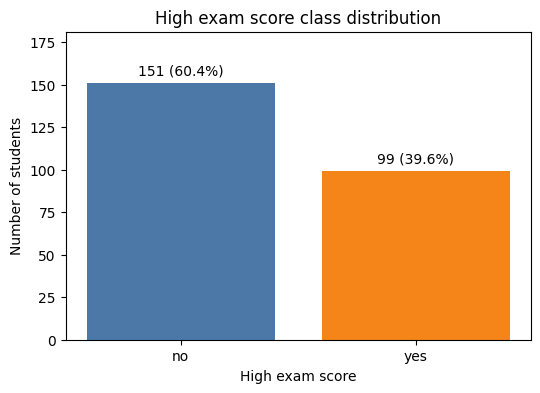

In [28]:
import matplotlib.pyplot as plt

class_counts = df["high_exam_score"].value_counts().reindex(["no", "yes"])
class_percentages = class_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=["#4C78A8", "#F58518"])
ax.set(title="High exam score class distribution", xlabel="High exam score", ylabel="Number of students")
ax.set_ylim(0, class_counts.max() * 1.2)

for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
            f"{count} ({percentage:.1f}%)", ha="center", va="bottom")

plt.show()

## Part 2: Choose the features

The seven features for the primary model are `study_hours_per_week`, `sleep_hours_per_night`, `attendance_rate`, `practice_problems_per_week`, `prior_programming_experience`, `study_group`, and `commute_minutes`. The target is `high_exam_score`. We will leave out `student_id`, `exam_score`, and `quiz_average` as instructed.

**Why should `student_id` normally not be used as a predictor?** It identifies a student's row; it does not measure study habits or preparation. A model might find a pattern in the ID numbers that happens to fit this dataset, but that pattern may not hold for new students.

**Why would using `exam_score` be a serious problem?** We created `high_exam_score` directly from `exam_score`: 80 or higher is **yes**, and below 80 is **no**. Giving the model `exam_score` would give it the answer in numerical form. For example, a score of 85 already tells us the label is **yes**. This is **target leakage**. The model could appear to perform extremely well, even on a held-out test set, because each test row would contain the value needed to calculate its answer. Such a result would not show whether study habits can predict a high score. We use `exam_score` to create the target, then exclude it from the model's inputs.

A useful question when choosing features is: *Would we know this value when we need to make the prediction?* The exam score would only be known after the exam.

In [29]:
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

X = df[feature_columns].copy()
y = df["high_exam_score"].copy()

print(f"Features: {X.shape[1]} columns | Target: {y.name} | Students: {len(y)}")

Features: 7 columns | Target: high_exam_score | Students: 250


## Part 3: Split the data

Reserve 20% of the students for testing and use the other 80% for training. Splitting `X` and `y` together keeps each student's features paired with the correct target. With 250 students, this gives 200 training rows and 50 test rows.

Use `random_state=42` so the random split is reproducible. Use `stratify=y` because this is a classification problem and the classes are somewhat uneven (60.4% **no**, 39.6% **yes**). Stratification keeps approximately the same class proportions in the training and test sets. The printed percentages below check the result.

Later preprocessing should learn its settings from the training data, then apply them to the test data. This keeps information from the test set out of training.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training students: {len(y_train)}")
print(f"Test students: {len(y_test)}")

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(1))

print("\nTest class percentages:")
print(y_test.value_counts(normalize=True).mul(100).round(1))

Training students: 200
Test students: 50

Training class percentages:
high_exam_score
no     60.5
yes    39.5
Name: proportion, dtype: float64

Test class percentages:
high_exam_score
no     60.0
yes    40.0
Name: proportion, dtype: float64


### Part 3 questions

1. **What is the purpose of the training set?** The training set contains 200 students. The model uses these examples to learn relationships between the seven features and `high_exam_score`. Any preprocessing that needs to learn from data, such as finding values to fill missing entries, should also be fitted using the training set.
2. **What is the purpose of the test set?** The test set contains 50 students kept aside during training. After the model is trained, we use it to see how well the model predicts labels for students it has not learned from.
3. **What does stratification do?** Stratification keeps the class balance approximately the same in both sets. In our split, the training set has 121 **no** and 79 **yes** students; the test set has 30 **no** and 20 **yes**. This helps make both sets representative of the full dataset's roughly 60% **no** and 40% **yes** balance.
4. **Why shouldn't we train the model using the test data?** If the model learns from the test students, those students are no longer an independent check. The resulting test score could look better than the model's performance on genuinely new students. We should also fit preprocessing on the training data, then apply it to the test data.

Repeatedly changing the model based on test results can also make us overfit our choices to the test set. We should keep this in mind when comparing later experiments.

## Part 4: Establish a baseline

Before training a model, establish a reference score using a simple rule: predict the most common **training** class for every test student. This baseline ignores the seven features. A later model should offer something useful beyond this rule.

In the training set, **no** is the majority class (121 **no**, 79 **yes**). Predicting **no** for all 50 test students correctly labels the 30 actual **no** students. Baseline test accuracy is **30 / 50 = 60%**. The training set's 60.5% **no** share is not the test accuracy; accuracy is measured against the test labels.

This baseline never identifies a **yes** student, which is one reason to inspect more than accuracy when we evaluate the trained model.

In [31]:
from sklearn.metrics import accuracy_score

# Learn the most common class from the training labels only.
majority_class = y_train.value_counts().idxmax()

# Give every test student that same prediction.
baseline_predictions = [majority_class] * len(y_test)

# Compare those predictions with the actual test labels.
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Training majority class: {majority_class}")
print(f"Baseline test accuracy: {baseline_accuracy:.1%}")

Training majority class: no
Baseline test accuracy: 60.0%


### Part 4 questions

1. **What is the majority class?** **No** is the majority class in the training set: 121 students are **no** and 79 are **yes**. We choose the baseline's prediction from the training labels.
2. **What accuracy does the majority-class baseline achieve?** It predicts **no** for every test student. Since 30 of the 50 test students are actually **no**, it gets **30 / 50 = 60% accuracy**.
3. **Why is this baseline useful?** It gives us a simple reference. A model could get 60% accuracy without using any student habits, so a score around 60% would not show that it learned something useful from the features.

Accuracy alone does not tell the whole story: this baseline gets every **yes** student wrong. When evaluating a trained model, check whether it improves on the baseline and how it handles both classes. With only 50 test students, each correct or incorrect prediction changes accuracy by 2 percentage points.

## Part 5: Preprocess the numerical features

The five numerical features are study hours, sleep hours, attendance rate, practice problems, and commute minutes. Some study-hour and sleep-hour values are missing. First, `SimpleImputer(strategy="median")` fills missing values using each column's **training-set median**. In this split, the training medians for study hours and sleep hours are 7.4 and 7.1.

Next, `StandardScaler` subtracts each column's training mean and divides by its training standard deviation. A standardized value near 0 is near the training mean; a value of +1 is about one standard deviation above it. This does **not** force values into the range 0 to 1. Scaling helps prevent differences in units, such as hours versus percentages, from dominating some models. We scale all five selected numerical features, including those with no missing values.

Fit both steps on `X_train` only, then use those learned values to transform `X_test`. The categorical features will be handled separately later; the target and excluded columns are not scaled.

In [32]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Learn fill values and scaling values from training data only.
X_train_numeric = numeric_pipeline.fit_transform(X_train[numeric_features])

# Apply those same values to the test data.
X_test_numeric = numeric_pipeline.transform(X_test[numeric_features])

print("Training numeric shape:", X_train_numeric.shape)
print("Test numeric shape:", X_test_numeric.shape)

Training numeric shape: (200, 5)
Test numeric shape: (50, 5)


### Preprocess the categorical features

The categorical features are `prior_programming_experience` and `study_group`. Fill blank entries with each column's most frequent **training** category, then use one-hot encoding to create a 0-or-1 indicator for each category. The literal value `None` in prior experience is a real category, not a missing value.

`ColumnTransformer` sends the five numerical columns through the numerical pipeline and the two categorical columns through the categorical pipeline. Fit the combined preprocessor on `X_train` only, then transform `X_test` using the same learned fill values, scaling values, and categories. `handle_unknown="ignore" allows a category that was unseen during training to be processed without an error.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "prior_programming_experience",
    "study_group",
]

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Learn fill values, scaling values, and categories from training data.
X_train_prepared = preprocessor.fit_transform(X_train)

# Apply the same preparation to test data without learning from it.
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (200, 10)
Prepared test shape: (50, 10)


### Part 5 questions

1. **Why do categorical variables need to be converted before Logistic Regression can use them?** Logistic Regression works with numerical inputs, so it cannot directly use text such as `Some` or `Yes`. We need to represent those categories as numbers without inventing a ranking between them.
2. **What does one-hot encoding do?** It creates a separate **0-or-1 column for each category**. For example, experience levels `None`, `Some`, and `Strong` become three indicator columns. A student with `Some` has a 1 in that column and 0 in the other two.
3. **Why do we need to handle missing values?** A blank gives the model no usable value for that feature. We fill blanks so we can keep those students and process their rows consistently. We learn the fill values from the **training set only** and apply them to the test set. The written experience category `None` remains a valid category; it is not a blank.
4. **What does `StandardScaler` do?** It subtracts each numerical feature's training mean and divides by its training standard deviation. This makes features measured in different units more comparable. The results are **not restricted to 0 through 1**; they can be negative or greater than 1.

## Part 6: Understand data scaling

1. **Why might scaling be useful for Logistic Regression?** Our numerical features use different units and ranges. Scaling puts them on comparable scales, which helps Logistic Regression learn efficiently. It also means the model's regularization does not treat a feature differently simply because it is measured in larger numbers, such as minutes rather than hours. Scaling does **not** make every feature equally important.
2. **Does standardization mean that all original values become numbers between 0 and 1?** **No.** Standardization measures how far a value is from its training mean in standard deviations. Values below the mean can be negative, and values well above it can be greater than 1. A 0-to-1 range is a different scaling method.
3. **Why should the test set not be used to calculate the mean and standard deviation used for scaling?** The test set is meant to represent students the model has not seen. Using it to calculate the mean or standard deviation would let information from those students influence preprocessing, making the evaluation less independent. We calculate those values from the training set and apply the same transformation to the test set.

## Part 7: Train a Logistic Regression classifier

Combine the existing preprocessor with `LogisticRegression` in one pipeline. When fitted on `X_train` and `y_train`, the pipeline prepares the original seven input columns and then learns to classify students as **yes** or **no**. The test set remains untouched for later evaluation. `max_iter=1000` is an upper limit on the iterations the classifier may need to finish training.

In [34]:
from sklearn.linear_model import LogisticRegression

log_reg_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

log_reg_pipeline.fit(X_train, y_train)

print("Model trained on", len(y_train), "students")
print("Classes:", log_reg_pipeline.named_steps["classifier"].classes_)

Model trained on 200 students
Classes: ['no' 'yes']


### Part 7 questions

1. **What does `.fit()` do?** `log_reg_pipeline.fit(X_train, y_train)` teaches the whole pipeline using the 200 training students. It first fits the preprocessing steps, transforms the training features, and then fits Logistic Regression using those features and the correct **yes** or **no** labels. It does not evaluate the model on the test set.
2. **What is learned from the training data?** The preprocessor learns the values needed to fill blanks, the mean and standard deviation for each numerical feature, and which categories need one-hot columns. Logistic Regression then learns weights and an intercept that connect those prepared features to the two classes. The **80-point rule** was set by us earlier; the model does not discover or change that rule.
3. **Why is it useful to put preprocessing and the classifier into one pipeline?** One pipeline runs the same steps in the right order every time. We can give it the original seven feature columns for training and, later, for prediction. It also helps prevent mistakes such as using different preparation for test students or fitting preprocessing on the test set.

## Part 8: Make predictions

Use the trained pipeline to predict each test student's class and compare it with the actual label. Then display the estimated probability of **yes**. The pipeline applies its learned preprocessing and classifier settings without fitting on the test data.

In [35]:
# Predict a class for each test student.
y_pred = log_reg_pipeline.predict(X_test)

prediction_results = pd.DataFrame({
    "actual_class": y_test,
    "predicted_class": y_pred,
}, index=X_test.index)

display(prediction_results.head(10))

# Find which probability column represents our "yes" class.
classes = log_reg_pipeline.named_steps["classifier"].classes_
yes_column = list(classes).index("yes")

# Obtain the estimated probability of "yes" for each test student.
yes_probabilities = log_reg_pipeline.predict_proba(X_test)[:, yes_column]

prediction_results["probability_of_yes"] = yes_probabilities

display(
    prediction_results.head(10).style.format({
        "probability_of_yes": "{:.1%}"
    })
)

,actual_class,predicted_class
113,yes,no
153,no,no
216,no,no
241,no,no
31,no,no
80,yes,no
140,yes,no
164,no,no
77,yes,yes
4,no,no


,actual_class,predicted_class,probability_of_yes
113,yes,no,46.9%
153,no,no,14.9%
216,no,no,28.9%
241,no,no,39.6%
31,no,no,22.9%
80,yes,no,49.6%
140,yes,no,48.4%
164,no,no,29.7%
77,yes,yes,82.0%
4,no,no,15.5%


### Part 8 questions

1. **What is the difference between `predict()` and `predict_proba()`?** `predict()` returns the chosen class for each student: **yes** or **no**. `predict_proba()` returns the model's estimated probability of each class. In our table, we display only the probability of **yes**.
2. **What does a predicted probability near 0.5 suggest?** A **yes** probability near 50% means the model has little preference between the two classes. The prediction is close to its decision boundary, so a small change in the features could change the predicted label.
3. **What does a predicted probability near 0.95 suggest?** A **yes** probability near 95% means the model strongly favors the **yes** class. It assigns about 5% probability to **no**. This is still an estimate and can be wrong; it does not mean the student will score 95 or that the model has 95% overall accuracy.

## Part 9: Evaluate the classifier

Compare the test predictions with the actual labels using accuracy, a confusion matrix, precision for **yes**, and recall for **yes**. Compare Logistic Regression's accuracy with the majority-class baseline from Part 4. In the confusion matrix, rows represent actual classes and columns represent predicted classes.

In [36]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
)

model_accuracy = accuracy_score(y_test, y_pred)

yes_precision = precision_score(
    y_test, y_pred, pos_label="yes", zero_division=0
)

yes_recall = recall_score(
    y_test, y_pred, pos_label="yes", zero_division=0
)

# Rows are actual classes; columns are predicted classes.
matrix = confusion_matrix(y_test, y_pred, labels=["no", "yes"])

confusion_table = pd.DataFrame(
    matrix,
    index=["Actual no", "Actual yes"],
    columns=["Predicted no", "Predicted yes"],
)

display(confusion_table)

print(f"Logistic Regression accuracy: {model_accuracy:.1%}")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.1%}")

accuracy_gain = (model_accuracy - baseline_accuracy) * 100
print(f"Accuracy improvement: {accuracy_gain:+.1f} percentage points")

print(f"Precision for yes: {yes_precision:.1%}")
print(f"Recall for yes: {yes_recall:.1%}")

,Predicted no,Predicted yes
Actual no,28,2
Actual yes,6,14


Logistic Regression accuracy: 84.0%
Majority-class baseline accuracy: 60.0%
Accuracy improvement: +24.0 percentage points
Precision for yes: 87.5%
Recall for yes: 70.0%


### Part 9 questions

1. **Accuracy: What fraction of all test predictions were correct?** The model correctly classified **42 of the 50 test students**, giving **84% accuracy**. Those correct predictions include 28 **no** students and 14 **yes** students.
2. **Precision: Among students predicted to have a high exam score, what fraction actually did?** The model predicted **yes** for 16 students. Of those, **14 actually had a high exam score**, giving **14 / 16 = 87.5% precision**. The other two were incorrectly predicted as **yes**.
3. **Recall: Among students who actually had a high exam score, what fraction did the model identify?** There were 20 actual **yes** students. The model identified **14 of them**, giving **14 / 20 = 70% recall**. It missed the other six.